## 1. Generate the fixed E1-like test ensemble

This cell generates 1805 independent Gaussian CMB realisations with

$$
N_{\mathrm{side}}=128,
\qquad
\ell_{\max}=300,
\qquad
N_{\phi}=512.
$$

Each Gaussian CMB field is

$$
\Delta T(\hat{\mathbf n})
=
\sum_{\ell m}
a_{\ell m}
Y_{\ell m}(\hat{\mathbf n}).
$$

Statistical isotropy gives

$$
\langle a_{\ell m}\rangle=0,
$$

and

$$
\left\langle
a_{\ell m}a^{*}_{\ell' m'}
\right\rangle
=
\delta_{\ell\ell'}
\delta_{mm'}
C_{\ell}.
$$

A fixed set of 13 antipodal E1-like circle pairs is injected:

$$
3 \text{ pairs at } \alpha=60^\circ,
\qquad
6 \text{ pairs at } \alpha=45^\circ,
\qquad
4 \text{ pairs at } \alpha=30^\circ.
$$

The circle positions are sampled at

$$
\phi_k
=
\frac{2\pi k}{N_{\phi}},
\qquad
k=0,\ldots,N_{\phi}-1.
$$

For an orientable reversed pair, the target circle is injected using

$$
T_j(\phi_k)
=
T_i(-\phi_k+\beta_{\star}).
$$

In discrete phase bins, this becomes

$$
k_j
=
(-k+\beta_{\star,\mathrm{bin}})
\mathbin{\bmod}
N_{\phi}.
$$

For the E1 topology, the identification is a pure translation with no rotational twist, so the injected physical phase is

$$
\beta_{\star}=0.
$$

Therefore,

$$
T_j(\phi_k)=T_i(-\phi_k).
$$

Any phase-bin offset stored by the code only aligns the different local coordinate bases of the two circles.

These maps provide a controlled ensemble for testing the MASTER-like recovery.

In [ ]:
from pathlib import Path

import healpy as hp
import numpy as np


# ==================================================
# Paths and settings
# ==================================================
root = Path("/hydrarepo/xluo/circles-in-the-sky")

power_spectrum_file = (
    root
    / "src"
    / "COM_PowerSpect_CMB-TT-full_R3.01.txt"
)

output_dir = (
    root
    / "inj_e1like_13pairs_1805_nside128_lmax300"
)

map_dir = (
    output_dir
    / "full_maps"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

map_dir.mkdir(
    parents=True,
    exist_ok=True,
)

geometry_file = (
    output_dir
    / "e1like_13pairs_geometry.dat"
)

summary_file = (
    output_dir
    / "generation_summary.dat"
)


# ==================================================
# Map settings
# ==================================================
nside_map = 128
nside_search = 128
nphi_ring = 512
lmax = 300

number_of_realisations = 1805
seed_base = 12345


# ==================================================
# E1-like cubic geometry
#
# 3 axis directions       -> alpha = 60 deg
# 6 face diagonals        -> alpha = 45 deg
# 4 body diagonals        -> alpha = 30 deg
# ==================================================
pair_groups = [
    (
        60.0,
        [
            (1, 0, 0),
            (0, 1, 0),
            (0, 0, 1),
        ],
    ),
    (
        45.0,
        [
            (1, 1, 0),
            (1, -1, 0),
            (1, 0, 1),
            (1, 0, -1),
            (0, 1, 1),
            (0, 1, -1),
        ],
    ),
    (
        30.0,
        [
            (1, 1, 1),
            (1, 1, -1),
            (1, -1, 1),
            (-1, 1, 1),
        ],
    ),
]


# ==================================================
# Geometry helpers
# ==================================================
def unit_vector(vector):

    vector = np.asarray(
        vector,
        dtype=float,
    )

    return (
        vector
        / np.linalg.norm(vector)
    )


def make_basis(centre):

    centre = unit_vector(
        centre
    )

    reference = np.array(
        [0.0, 0.0, 1.0]
    )

    if abs(
        np.dot(
            reference,
            centre,
        )
    ) > 0.9:

        reference = np.array(
            [1.0, 0.0, 0.0]
        )

    e1 = (
        reference
        - np.dot(
            reference,
            centre,
        )
        * centre
    )

    e1 = unit_vector(
        e1
    )

    e2 = unit_vector(
        np.cross(
            centre,
            e1,
        )
    )

    return e1, e2


def circle_vectors(
    centre,
    alpha_rad,
    phases,
):

    e1, e2 = make_basis(
        centre
    )

    vectors = (
        np.cos(alpha_rad)
        * centre[:, None]
        + np.sin(alpha_rad)
        * (
            np.cos(phases)[None, :]
            * e1[:, None]
            + np.sin(phases)[None, :]
            * e2[:, None]
        )
    )

    return vectors


def sample_circle(
    sky_map,
    centre,
    alpha_rad,
):

    phases = (
        2.0
        * np.pi
        * np.arange(nphi_ring)
        / nphi_ring
    )

    vectors = circle_vectors(
        centre=centre,
        alpha_rad=alpha_rad,
        phases=phases,
    )

    theta = np.arccos(
        np.clip(
            vectors[2],
            -1.0,
            1.0,
        )
    )

    phi = np.mod(
        np.arctan2(
            vectors[1],
            vectors[0],
        ),
        2.0 * np.pi,
    )

    return hp.get_interp_val(
        sky_map,
        theta,
        phi,
    )


def periodic_profile(
    profile,
    phases,
):

    coordinate = (
        np.mod(
            phases,
            2.0 * np.pi,
        )
        * len(profile)
        / (2.0 * np.pi)
    )

    index_0 = (
        np.floor(coordinate)
        .astype(int)
    )

    fraction = (
        coordinate
        - np.floor(coordinate)
    )

    index_1 = (
        index_0 + 1
    ) % len(profile)

    return (
        (1.0 - fraction)
        * profile[index_0]
        + fraction
        * profile[index_1]
    )


def paint_circle(
    sky_map,
    centre,
    alpha_rad,
    profile,
):

    output = sky_map.copy()

    pixel_size_rad = hp.nside2resol(
        nside_map
    )

    core_half_width = (
        2.0
        * pixel_size_rad
    )

    taper_width = (
        1.0
        * pixel_size_rad
    )

    outer_half_width = (
        core_half_width
        + taper_width
    )

    pixels = hp.query_disc(
        nside=nside_map,
        vec=centre,
        radius=(
            alpha_rad
            + outer_half_width
        ),
        inclusive=True,
    )

    vectors = np.asarray(
        hp.pix2vec(
            nside_map,
            pixels,
        ),
        dtype=float,
    )

    cos_radius = np.clip(
        np.dot(
            centre,
            vectors,
        ),
        -1.0,
        1.0,
    )

    radius = np.arccos(
        cos_radius
    )

    distance = np.abs(
        radius
        - alpha_rad
    )

    keep = (
        distance
        < outer_half_width
    )

    pixels = pixels[keep]
    vectors = vectors[:, keep]
    cos_radius = cos_radius[keep]
    distance = distance[keep]

    e1, e2 = make_basis(
        centre
    )

    radial = (
        vectors
        - centre[:, None]
        * cos_radius[None, :]
    )

    radial = (
        radial
        / np.linalg.norm(
            radial,
            axis=0,
        )[None, :]
    )

    local_phase = np.mod(
        np.arctan2(
            np.dot(
                e2,
                radial,
            ),
            np.dot(
                e1,
                radial,
            ),
        ),
        2.0 * np.pi,
    )

    desired = periodic_profile(
        profile,
        local_phase,
    )

    weight = np.zeros(
        len(pixels),
        dtype=float,
    )

    core = (
        distance
        <= core_half_width
    )

    taper = (
        (distance > core_half_width)
        & (distance < outer_half_width)
    )

    weight[core] = 1.0

    taper_coordinate = (
        distance[taper]
        - core_half_width
    ) / taper_width

    weight[taper] = (
        0.5
        * (
            1.0
            + np.cos(
                np.pi
                * taper_coordinate
            )
        )
    )

    output[pixels] = (
        (1.0 - weight)
        * output[pixels]
        + weight
        * desired
    )

    return output


# ==================================================
# Search-grid centres
# ==================================================
search_pixels = np.arange(
    hp.nside2npix(
        nside_search
    )
)

search_vectors = np.asarray(
    hp.pix2vec(
        nside_search,
        search_pixels,
    ),
    dtype=float,
)


def snap_to_search_grid(
    direction,
):

    direction = unit_vector(
        direction
    )

    dots = np.dot(
        direction,
        search_vectors,
    )

    pixel = int(
        np.argmax(dots)
    )

    centre = (
        search_vectors[:, pixel]
    )

    offset_deg = np.degrees(
        np.arccos(
            np.clip(
                dots[pixel],
                -1.0,
                1.0,
            )
        )
    )

    return (
        pixel,
        centre,
        offset_deg,
    )


def expected_phase_bin(
    centre_i,
    centre_j,
):

    e1_i, _ = make_basis(
        centre_i
    )

    e1_j, e2_j = make_basis(
        centre_j
    )

    beta_rad = np.mod(
        np.arctan2(
            np.dot(
                e2_j,
                e1_i,
            ),
            np.dot(
                e1_j,
                e1_i,
            ),
        ),
        2.0 * np.pi,
    )

    beta_bin = int(
        np.rint(
            beta_rad
            * nphi_ring
            / (2.0 * np.pi)
        )
    ) % nphi_ring

    beta_deg = np.degrees(
        beta_rad
    )

    return (
        beta_bin,
        beta_deg,
    )


# ==================================================
# Planck spectrum:
# D_ell [microK^2] -> C_ell [K^2]
# ==================================================
spectrum = np.loadtxt(
    power_spectrum_file,
    comments="#",
)

cl = np.zeros(
    lmax + 1,
    dtype=float,
)

for (
    ell,
    dl_microkelvin_squared,
) in spectrum[:, :2]:

    ell = int(ell)

    if 2 <= ell <= lmax:

        cl[ell] = (
            dl_microkelvin_squared
            * 1.0e-12
            * 2.0
            * np.pi
            / (
                ell
                * (ell + 1.0)
            )
        )

cl[0] = 0.0
cl[1] = 0.0


# ==================================================
# Construct the fixed 13-pair geometry once
# ==================================================
pair_geometry = []
geometry_rows = []

pair_id = 1

for (
    alpha_deg,
    directions,
) in pair_groups:

    alpha_rad = np.radians(
        alpha_deg
    )

    for direction in directions:

        (
            pixel_i,
            centre_i,
            offset_i_deg,
        ) = snap_to_search_grid(
            direction
        )

        (
            pixel_j,
            centre_j,
            offset_j_deg,
        ) = snap_to_search_grid(
            -centre_i
        )

        separation_deg = np.degrees(
            np.arccos(
                np.clip(
                    np.dot(
                        centre_i,
                        centre_j,
                    ),
                    -1.0,
                    1.0,
                )
            )
        )

        if separation_deg < 179.0:

            raise ValueError(
                f"Pair {pair_id:02d} "
                "is not antipodal."
            )

        (
            beta_bin,
            beta_deg,
        ) = expected_phase_bin(
            centre_i,
            centre_j,
        )

        theta_i, phi_i = hp.pix2ang(
            nside_search,
            pixel_i,
        )

        theta_j, phi_j = hp.pix2ang(
            nside_search,
            pixel_j,
        )

        pair_geometry.append(
            {
                "pair_id": pair_id,
                "alpha_deg": alpha_deg,
                "alpha_rad": alpha_rad,
                "pixel_i": pixel_i,
                "centre_i": centre_i,
                "pixel_j": pixel_j,
                "centre_j": centre_j,
                "beta_bin": beta_bin,
            }
        )

        geometry_rows.append(
            (
                pair_id,
                alpha_deg,
                pixel_i,
                np.degrees(theta_i),
                np.degrees(phi_i),
                pixel_j,
                np.degrees(theta_j),
                np.degrees(phi_j),
                separation_deg,
                beta_bin,
                beta_deg,
                offset_i_deg,
                offset_j_deg,
            )
        )

        print(
            f"pair={pair_id:02d}  "
            f"alpha={alpha_deg:5.1f}  "
            f"pixels=({pixel_i}, {pixel_j})  "
            f"beta_bin={beta_bin:3d}"
        )

        pair_id += 1


if len(pair_geometry) != 13:

    raise RuntimeError(
        "Expected 13 circle pairs, "
        f"constructed {len(pair_geometry)}."
    )


# ==================================================
# Save the fixed geometry once
# ==================================================
geometry_header = (
    "pair_id alpha_deg "
    "pixel_i theta_i_deg phi_i_deg "
    "pixel_j theta_j_deg phi_j_deg "
    "separation_deg "
    "expected_beta_bin expected_beta_deg "
    "offset_i_deg offset_j_deg"
)

np.savetxt(
    geometry_file,
    np.asarray(
        geometry_rows
    ),
    header=geometry_header,
    comments="# ",
    fmt=(
        "%d %.8f "
        "%d %.8f %.8f "
        "%d %.8f %.8f "
        "%.8f "
        "%d %.8f "
        "%.8f %.8f"
    ),
)


# ==================================================
# Generate 1805 independent E1-like maps
# ==================================================
ring_indices = np.arange(
    nphi_ring
)

for realisation in range(
    number_of_realisations
):

    seed = (
        seed_base
        + realisation
    )

    output_file = (
        map_dir
        / (
            f"e1like_r{realisation:04d}_"
            f"nside{nside_map}_"
            f"lmax{lmax}.fits"
        )
    )

    # Continue safely after interruption
    if output_file.exists():

        print(
            f"[{realisation + 1:04d}/"
            f"{number_of_realisations:04d}] "
            f"already exists: "
            f"{output_file.name}"
        )

        continue

    np.random.seed(
        seed
    )

    # ----------------------------------------------
    # Independent Gaussian CMB background
    # ----------------------------------------------
    background_map = hp.synfast(
        cl,
        nside=nside_map,
        lmax=lmax,
        pixwin=False,
        verbose=False,
        new=True,
    )

    combined_map = (
        background_map.copy()
    )

    # ----------------------------------------------
    # Inject the same fixed 13 pairs
    # ----------------------------------------------
    for pair in pair_geometry:

        source_profile = sample_circle(
            sky_map=background_map,
            centre=pair["centre_i"],
            alpha_rad=pair["alpha_rad"],
        )

        target_indices = (
            -ring_indices
            + pair["beta_bin"]
        ) % nphi_ring

        target_profile = (
            source_profile[
                target_indices
            ]
        )

        combined_map = paint_circle(
            sky_map=combined_map,
            centre=pair["centre_j"],
            alpha_rad=pair["alpha_rad"],
            profile=target_profile,
        )

    # ----------------------------------------------
    # Save full injected map
    # ----------------------------------------------
    hp.write_map(
        output_file,
        combined_map,
        overwrite=False,
        dtype=np.float32,
    )

    print(
        f"[{realisation + 1:04d}/"
        f"{number_of_realisations:04d}] "
        f"seed={seed}  "
        f"saved={output_file.name}"
    )


# ==================================================
# Save generation summary
# ==================================================
with summary_file.open(
    "w"
) as file:

    file.write(
        "# realisation seed map_file\n"
    )

    for realisation in range(
        number_of_realisations
    ):

        seed = (
            seed_base
            + realisation
        )

        map_name = (
            f"e1like_r{realisation:04d}_"
            f"nside{nside_map}_"
            f"lmax{lmax}.fits"
        )

        file.write(
            f"{realisation:04d} "
            f"{seed:d} "
            f"{map_name}\n"
        )


# ==================================================
# Final check
# ==================================================
generated_files = sorted(
    map_dir.glob(
        "e1like_r*_nside128_lmax300.fits"
    )
)

print()
print("=" * 70)
print(
    "Generated maps:",
    len(generated_files),
)
print(
    "Expected maps:",
    number_of_realisations,
)
print(
    "Geometry file:",
    geometry_file,
)
print(
    "Summary file:",
    summary_file,
)
print(
    "Map directory:",
    map_dir,
)
print("=" * 70)

if (
    len(generated_files)
    != number_of_realisations
):

    raise RuntimeError(
        "The expected number of maps "
        "was not generated."
    )

print("Done.")

## 2. Construct the circle-mode coupling matrices

For each circle pair, the Galactic mask defines two ring windows:

$$
0\leq w_{i,k},w_{j,k}\leq 1,
\qquad
k=0,\ldots,N_\phi-1.
$$

The masked circle temperatures are

$$
\widehat{T}_{i,k}=w_{i,k}T_{i,k},
\qquad
\widehat{T}_{j,k}=w_{j,k}T_{j,k}.
$$

The Fourier modes of each window are

$$
W_{i,p}
=
\frac{1}{N_\phi}
\sum_{k=0}^{N_\phi-1}
w_{i,k}e^{-ip\phi_k},
$$

and similarly for $W_{j,p}$.

Multiplication by the window in real space produces convolution in circle Fourier space:

$$
\widehat{T}_{i,m}
=
\sum_n
W_{i,m-n}T_{i,n},
$$

$$
\widehat{T}_{j,m}
=
\sum_n
W_{j,m-n}T_{j,n},
$$

where all mode differences are understood modulo $N_\phi$.

For the orientable reversed pair, define the full mode products

$$
C^{ij}_n=T_{i,n}T_{j,n},
\qquad
C^{ii}_n=|T_{i,n}|^2,
\qquad
C^{jj}_n=|T_{j,n}|^2.
$$

Statistical isotropy gives

$$
\left\langle
T_{i,n}T_{j,n'}
\right\rangle
=
\delta_{nn'}C^{ij}_n.
$$

The three coupling matrices are therefore

$$
\left(M_{ij}\right)_{mn}
=
W_{i,m-n}W_{j,m-n},
$$

$$
\left(M_{ii}\right)_{mn}
=
\left|W_{i,m-n}\right|^2,
$$

$$
\left(M_{jj}\right)_{mn}
=
\left|W_{j,m-n}\right|^2.
$$

The ensemble MASTER-like relations are

$$
\left\langle
\widehat{\mathbf C}^{\,ij}
\right\rangle
=
M_{ij}\mathbf C^{ij},
$$

$$
\left\langle
\widehat{\mathbf C}^{\,ii}
\right\rangle
=
M_{ii}\mathbf C^{ii},
\qquad
\left\langle
\widehat{\mathbf C}^{\,jj}
\right\rangle
=
M_{jj}\mathbf C^{jj}.
$$

For one realisation, off-diagonal mode products produce a fluctuation term:

$$
\widehat{\mathbf C}^{\,ij,(r)}
=
M_{ij}\mathbf C^{ij,(r)}
+
\boldsymbol{\epsilon}^{\,ij,(r)}.
$$

The 1800 realisations are used to test the ensemble MASTER approximation against the directly measured masked quantities.

They do not determine the coupling matrices: $M_{ij}$, $M_{ii}$ and $M_{jj}$ depend only on the circle windows and geometry.

For the E1 matching convention $\beta_\star=0$, the jointly lost fraction is

$$
f_{\mathrm{lost}}
=
1-
\frac{1}{N_\phi}
\sum_{k=0}^{N_\phi-1}
w_{i,k}w_{j,-k}.
$$

The ring pixels, windows, lost fraction and three coupling matrices are saved separately for each circle pair.

In [ ]:
from pathlib import Path

import healpy as hp
import numpy as np
import pandas as pd
from IPython.display import display


# ==================================================
# Paths and settings
# ==================================================
root = Path("/hydrarepo/xluo/circles-in-the-sky")

ensemble_dir = (
    root
    / "inj_e1like_13pairs_1805_nside128_lmax300"
)

full_map_dir = ensemble_dir / "full_maps"

geometry_file = (
    ensemble_dir
    / "e1like_13pairs_geometry.dat"
)

mask_file = (
    root
    / "src"
    / "COM_Mask_CMB-common-Mask-Int_128_R3.00.fits"
)

relative_error_table_file = (
    ensemble_dir
    / "e1_13pairs_f_lost_and_relative_error.dat"
)

NPHI = 512
N_CALIBRATION = 1800
NSIDE = 128
LMAX = 300
M_MIN = 2
MASK_THRESHOLD = 0.5


# ==================================================
# Helpers
# ==================================================
def realisation_id(path):
    return int(
        path.stem
        .split("_r")[1]
        .split("_")[0]
    )


def make_basis(centre):
    centre = np.asarray(centre, dtype=float)
    centre /= np.linalg.norm(centre)

    reference = np.array([0.0, 0.0, 1.0])

    if abs(np.dot(reference, centre)) > 0.9:
        reference = np.array([1.0, 0.0, 0.0])

    e1 = reference - np.dot(reference, centre) * centre
    e1 /= np.linalg.norm(e1)

    e2 = np.cross(centre, e1)

    return e1, e2


def circle_pixels(nside, centre, alpha, nphi):
    e1, e2 = make_basis(centre)

    phase = 2.0 * np.pi * np.arange(nphi) / nphi

    vectors = (
        np.cos(alpha) * centre[:, None]
        + np.sin(alpha)
        * (
            np.cos(phase)[None, :] * e1[:, None]
            + np.sin(phase)[None, :] * e2[:, None]
        )
    )

    return hp.vec2pix(
        nside,
        vectors[0],
        vectors[1],
        vectors[2],
        nest=False,
    )


def relative_error(measured, predicted):
    denominator = np.linalg.norm(measured)

    if denominator == 0.0:
        return np.nan

    return np.linalg.norm(measured - predicted) / denominator


def read_geometry_table(path):
    values = np.genfromtxt(
        path,
        names=True,
        dtype=None,
        encoding=None,
    )

    names = values.dtype.names
    pair_name = "pair" if "pair" in names else "pair_id"

    beta_deg = (
        values["beta_deg"]
        if "beta_deg" in names
        else np.zeros(len(values))
    )

    geometry = pd.DataFrame(
        {
            "Pair": values[pair_name].astype(int),
            "alpha_deg": values["alpha_deg"],
            "theta_i_deg": values["theta_i_deg"],
            "phi_i_deg": values["phi_i_deg"],
            "theta_j_deg": values["theta_j_deg"],
            "phi_j_deg": values["phi_j_deg"],
            "beta_deg": beta_deg,
        }
    ).sort_values("Pair")

    if len(geometry) != 13:
        raise RuntimeError(
            f"Expected 13 E1 pairs, found {len(geometry)}."
        )

    return geometry.reset_index(drop=True)


# ==================================================
# Inputs
# ==================================================
geometry = read_geometry_table(geometry_file)

mask = hp.read_map(
    mask_file,
    field=0,
    dtype=np.float64,
)

if hp.get_nside(mask) != NSIDE:
    raise ValueError(
        f"Mask NSIDE={hp.get_nside(mask)}, expected {NSIDE}."
    )

all_full_files = sorted(
    full_map_dir.glob(
        "e1like_r*_nside128_lmax300.fits"
    ),
    key=realisation_id,
)

calibration_files = [
    path
    for path in all_full_files
    if realisation_id(path) < N_CALIBRATION
]

if len(calibration_files) != N_CALIBRATION:
    raise RuntimeError(
        f"Expected {N_CALIBRATION} calibration maps, "
        f"found {len(calibration_files)}."
    )

m_index = np.arange(NPHI)[:, None]
n_index = np.arange(NPHI)[None, :]
m_minus_n = (m_index - n_index) % NPHI
search_modes = np.arange(M_MIN, NPHI // 2 + 1)


# ==================================================
# One pair at a time
# ==================================================
summary_rows = []

for row in geometry.itertuples(index=False):
    pair = int(row.Pair)
    alpha = np.deg2rad(row.alpha_deg)

    centre_i = np.asarray(
        hp.ang2vec(
            np.deg2rad(row.theta_i_deg),
            np.deg2rad(row.phi_i_deg),
        ),
        dtype=float,
    )

    centre_j = np.asarray(
        hp.ang2vec(
            np.deg2rad(row.theta_j_deg),
            np.deg2rad(row.phi_j_deg),
        ),
        dtype=float,
    )

    pix_ring_i = circle_pixels(
        NSIDE,
        centre_i,
        alpha,
        NPHI,
    )

    pix_ring_j = circle_pixels(
        NSIDE,
        centre_j,
        alpha,
        NPHI,
    )

    w_i = (
        mask[pix_ring_i] >= MASK_THRESHOLD
    ).astype(float)

    w_j = (
        mask[pix_ring_j] >= MASK_THRESHOLD
    ).astype(float)

    beta_bin = int(
        np.rint(
            (row.beta_deg % 360.0)
            * NPHI
            / 360.0
        )
    ) % NPHI

    # Orientable matching: k' = beta_bin - k (mod NPHI).
    matched_j_index = (
        beta_bin - np.arange(NPHI)
    ) % NPHI

    f_lost = float(
        np.mean(
            (w_i < 0.5)
            | (w_j[matched_j_index] < 0.5)
        )
    )

    W_i = np.fft.fft(w_i) / NPHI
    W_j = np.fft.fft(w_j) / NPHI

    A_i = W_i[m_minus_n]
    A_j = W_j[m_minus_n]

    M_ij = W_i[m_minus_n] * W_j[m_minus_n]
    M_ii = np.abs(W_i[m_minus_n]) ** 2
    M_jj = np.abs(W_j[m_minus_n]) ** 2

    cross_covariance_sum = np.zeros(
        (NPHI, NPHI),
        dtype=np.complex128,
    )
    power_i_covariance_sum = np.zeros_like(
        cross_covariance_sum
    )
    power_j_covariance_sum = np.zeros_like(
        cross_covariance_sum
    )

    cross_masked_sum = np.zeros(
        NPHI,
        dtype=np.complex128,
    )
    power_i_masked_sum = np.zeros(NPHI)
    power_j_masked_sum = np.zeros(NPHI)

    for count, map_file in enumerate(
        calibration_files,
        start=1,
    ):
        sky_map = hp.read_map(
            map_file,
            field=0,
            dtype=np.float64,
        )

        ring_i = sky_map[pix_ring_i]
        ring_j = sky_map[pix_ring_j]

        T_i = np.fft.fft(ring_i) / NPHI
        T_j = np.fft.fft(ring_j) / NPHI

        T_i_masked = np.fft.fft(
            w_i * ring_i
        ) / NPHI

        T_j_masked = np.fft.fft(
            w_j * ring_j
        ) / NPHI

        cross_covariance_sum += np.outer(T_i, T_j)
        power_i_covariance_sum += np.outer(
            np.conj(T_i),
            T_i,
        )
        power_j_covariance_sum += np.outer(
            np.conj(T_j),
            T_j,
        )

        cross_masked_sum += T_i_masked * T_j_masked
        power_i_masked_sum += np.abs(T_i_masked) ** 2
        power_j_masked_sum += np.abs(T_j_masked) ** 2

        if count % 500 == 0 or count == N_CALIBRATION:
            print(
                f"Pair {pair}: {count}/{N_CALIBRATION}"
            )

    cross_covariance = (
        cross_covariance_sum / N_CALIBRATION
    )
    power_i_covariance = (
        power_i_covariance_sum / N_CALIBRATION
    )
    power_j_covariance = (
        power_j_covariance_sum / N_CALIBRATION
    )

    cross_masked_mean = (
        cross_masked_sum / N_CALIBRATION
    )
    power_i_masked_mean = (
        power_i_masked_sum / N_CALIBRATION
    )
    power_j_masked_mean = (
        power_j_masked_sum / N_CALIBRATION
    )

    C_ij_mean = np.diag(cross_covariance)
    P_i_mean = np.real(np.diag(power_i_covariance))
    P_j_mean = np.real(np.diag(power_j_covariance))

    cross_exact = np.einsum(
        "mk,kl,ml->m",
        A_i,
        cross_covariance,
        A_j,
        optimize=True,
    )
    power_i_exact = np.einsum(
        "mk,kl,ml->m",
        np.conj(A_i),
        power_i_covariance,
        A_i,
        optimize=True,
    )
    power_j_exact = np.einsum(
        "mk,kl,ml->m",
        np.conj(A_j),
        power_j_covariance,
        A_j,
        optimize=True,
    )

    cross_master = M_ij @ C_ij_mean
    power_i_master = M_ii @ P_i_mean
    power_j_master = M_jj @ P_j_mean

    step3_file = (
        ensemble_dir
        / f"pair{pair:02d}_ensemble_mixing_1800cal.npz"
    )

    np.savez(
        step3_file,
        pair=pair,
        alpha_deg=row.alpha_deg,
        theta_i_deg=row.theta_i_deg,
        phi_i_deg=row.phi_i_deg,
        theta_j_deg=row.theta_j_deg,
        phi_j_deg=row.phi_j_deg,
        beta_deg=row.beta_deg,
        beta_bin=beta_bin,
        pix_ring_i=pix_ring_i,
        pix_ring_j=pix_ring_j,
        w_i=w_i,
        w_j=w_j,
        M_ij=M_ij,
        M_ii=M_ii,
        M_jj=M_jj,
        f_lost=f_lost,
    )

    summary_rows.append(
        {
            "Pair": pair,
            "alpha_deg": row.alpha_deg,
            "f_lost": f_lost,
            "Invert": "yes" if f_lost <= 0.5 else "no",
            "Cross exact relative error": relative_error(
                cross_masked_mean[search_modes],
                cross_exact[search_modes],
            ),
            "Cross MASTER relative error": relative_error(
                cross_masked_mean[search_modes],
                cross_master[search_modes],
            ),
            "Circle i power exact relative error": relative_error(
                power_i_masked_mean[search_modes],
                power_i_exact[search_modes],
            ),
            "Circle i power MASTER relative error": relative_error(
                power_i_masked_mean[search_modes],
                power_i_master[search_modes],
            ),
            "Circle j power exact relative error": relative_error(
                power_j_masked_mean[search_modes],
                power_j_exact[search_modes],
            ),
            "Circle j power MASTER relative error": relative_error(
                power_j_masked_mean[search_modes],
                power_j_master[search_modes],
            ),
        }
    )


pair_table = pd.DataFrame(summary_rows).sort_values("Pair")

pair_table.to_csv(
    relative_error_table_file,
    sep="\t",
    index=False,
    float_format="%.10e",
)

display(pair_table)
print("Saved:", relative_error_table_file)

## 3. Define the regularised inverse and recover $S(\beta)$

The coupling matrices are circulant because their elements depend only on $m-n$.

A circulant matrix is diagonalised by the discrete Fourier transform. Its eigenvalues are

$$
\mu_q
=
\operatorname{DFT}
\left(M_{:,0}\right)_q.
$$

In the coupling-matrix eigenbasis,

$$
\widehat{C}^{F}_q
=
\mu_q C^{F}_q,
$$

where $\widehat{C}^{F}_q$ is the masked quantity.

The exact inverse,

$$
C^{F}_q
=
\frac{\widehat{C}^{F}_q}{\mu_q},
$$

is unstable when $|\mu_q|$ is small and undefined when $\mu_q=0$.

We therefore minimise the Tikhonov functional

$$
\left|
\mu_q x_q-\widehat{C}^{F}_q
\right|^2
+
\lambda^2|x_q|^2.
$$

The recovered eigenmode is

$$
\widetilde{C}^{F}_q
=
\frac{\mu_q^*}
{|\mu_q|^2+\lambda^2}
\widehat{C}^{F}_q.
$$

Define the regularised inverse response

$$
R_q(\lambda)
=
\frac{\mu_q^*}
{|\mu_q|^2+\lambda^2}.
$$

The regularisation scale is written as

$$
\lambda
=
f_{\mathrm{reg}}
\max_q|\mu_q|.
$$

The recovered mode products are obtained using

$$
\widetilde{\mathbf C}
=
\operatorname{DFT}^{-1}
\left[
R_q(\lambda)
\operatorname{DFT}
\left(\widehat{\mathbf C}\right)_q
\right].
$$

This inversion is applied separately to

$$
\widehat{\mathbf C}^{\,ij},
\qquad
\widehat{\mathbf C}^{\,ii},
\qquad
\widehat{\mathbf C}^{\,jj},
$$

using the corresponding matrices $M_{ij}$, $M_{ii}$ and $M_{jj}$.

The recovered circle statistic is then

$$
\widetilde{S}_{ij}(\beta)
=
\frac{
2\operatorname{Re}
\left[
\displaystyle\sum_m
|m|\,
\widetilde{C}^{ij}_m
e^{im\beta}
\right]
}{
\displaystyle\sum_m
|m|
\left(
\widetilde{C}^{ii}_m
+
\widetilde{C}^{jj}_m
\right)
}.
$$

Modes with

$$
|m|<m_{\min}=2
$$

are assigned zero weight.

This cell only defines how to apply a supplied $f_{\mathrm{reg}}$. It hasn't determine the optimal regularisation parameter.

In [ ]:
import numpy as np


def apply_regularised_inverse(
    masked_quantities,
    coupling_eigenvalues,
    regularisation_fraction,
):
    """
    Apply the Tikhonov-regularised inverse of a circulant
    coupling matrix.
    """

    maximum_eigenvalue = np.max(
        np.abs(coupling_eigenvalues)
    )

    if maximum_eigenvalue == 0.0:
        raise ValueError(
            "All coupling eigenvalues are zero."
        )

    regularisation_scale = (
        regularisation_fraction
        * maximum_eigenvalue
    )

    inverse_filter = (
        np.conj(coupling_eigenvalues)
        / (
            np.abs(coupling_eigenvalues) ** 2
            + regularisation_scale**2
        )
    )

    recovered_quantities = np.fft.ifft(
        np.fft.fft(
            masked_quantities,
            axis=-1,
        )
        * inverse_filter,
        axis=-1,
    )

    return recovered_quantities


def calculate_S_curves_from_mode_products(
    cross_products,
    circle_i_powers,
    circle_j_powers,
    m_min=2,
):
    """
    Calculate S(beta) from reconstructed cross-products
    and auto-powers.
    """

    cross_products = np.atleast_2d(
        cross_products
    )

    circle_i_powers = np.atleast_2d(
        circle_i_powers
    )

    circle_j_powers = np.atleast_2d(
        circle_j_powers
    )

    nphi = cross_products.shape[-1]

    mode_index = np.arange(nphi)

    physical_mode_number = np.minimum(
        mode_index,
        nphi - mode_index,
    ).astype(float)

    mode_weight = physical_mode_number.copy()

    mode_weight[
        physical_mode_number < m_min
    ] = 0.0

    weighted_cross_products = (
        mode_weight[None, :]
        * cross_products
    )

    numerators = (
        2.0
        * nphi
        * np.real(
            np.fft.ifft(
                weighted_cross_products,
                axis=-1,
            )
        )
    )

    denominators = np.real(
        np.sum(
            mode_weight[None, :]
            * (
                circle_i_powers
                + circle_j_powers
            ),
            axis=-1,
        )
    )

    valid = (
        np.isfinite(denominators)
        & (denominators > 0.0)
    )

    S_curves = np.full(
        numerators.shape,
        np.nan,
        dtype=float,
    )

    S_curves[valid] = (
        numerators[valid]
        / denominators[valid, None]
    )

    return S_curves, valid

## 4. Apply the reconstruction to the E1 foreground-residual maps

This cell applies the regularised MASTER-like reconstruction to the 10 E1 foreground-residual realisations.

For each circle pair:

1. Load the saved ring pixels and coupling matrices.
2. Read the fixed regularisation fraction.
3. Skip the pair if $f_{\mathrm{lost}}>0.5$.
4. Reconstruct the cross-product and two circle powers.
5. Calculate the full and recovered $S(\beta)$ curves.
6. Compare their peak values and peak positions.

The circular phase error is

$$
\Delta\beta_{\mathrm{bin}}
=
\min
\left(
|\widetilde{\beta}_{\max}-\beta_{\max}|,
\,
N_\phi-
|\widetilde{\beta}_{\max}-\beta_{\max}|
\right).
$$

The full-curve error is

$$
\operatorname{RMSE}[S(\beta)]
=
\sqrt{
\frac{1}{N_\phi}
\sum_\beta
\left[
\widetilde{S}(\beta)-S(\beta)
\right]^2
}.
$$

The calibrated median bias is removed from the recovered peak:

$$
\widetilde{S}_{\max}^{\,\mathrm{corrected}}
=
\widetilde{S}_{\max}^{\,\mathrm{raw}}
-
\operatorname{median}
\left(
\widetilde{S}_{\max}-S_{\max}
\right)_{\mathrm{cal}}.
$$

The full-ring quantities are used only as the known reference for this validation test.

This is the fixed-parameter baseline. Later, the fixed E1-calibrated value will be replaced by a GCV or robust-GCV value selected separately for each trial geometry.

In [ ]:
fixed_parameter_file = (
    ensemble_dir
    / "e1_13pairs_inverse_on_100_masked_nulls.dat"
)

fixed_parameters = pd.read_csv(
    fixed_parameter_file,
    sep="\t",
)

pair_by_f_lost = dict(
    zip(
        pair_table["f_lost"].round(6),
        pair_table["Pair"],
    )
)

fixed_parameters["Pair"] = (
    fixed_parameters["f_lost"]
    .round(6)
    .map(pair_by_f_lost)
)

if fixed_parameters["Pair"].isna().any():
    raise RuntimeError(
        "Could not identify every pair from f_lost."
    )

fixed_parameters["Pair"] = (
    fixed_parameters["Pair"].astype(int)
)

fixed_parameters = (
    fixed_parameters.loc[
        fixed_parameters["Status"] == "inverted"
    ]
    .drop_duplicates("Pair")
    .set_index("Pair")
)

e1_fgres_files = sorted(
    (root / "src").glob("E1_fgres_r???.fits")
)

if len(e1_fgres_files) != 10:
    raise RuntimeError(
        f"Expected 10 E1_fgres maps, found {len(e1_fgres_files)}."
    )

e1_fgres_rows = []

for map_file in e1_fgres_files:
    realisation = map_file.stem.split("_r")[-1]

    full_map = hp.read_map(
        map_file,
        field=0,
        dtype=np.float64,
    )

    if hp.get_nside(full_map) != NSIDE:
        raise ValueError(
            f"{map_file.name}: NSIDE="
            f"{hp.get_nside(full_map)}, expected {NSIDE}."
        )

    # Apply the Galactic mask before M^{-1}.
    masked_map = full_map.copy()
    masked_map[mask < MASK_THRESHOLD] = 0.0

    for pair_row in pair_table.itertuples(index=False):
        pair = int(pair_row.Pair)
        f_lost = float(pair_row.f_lost)

        if f_lost > 0.5:
            e1_fgres_rows.append(
                {
                    "Realisation": f"r{realisation}",
                    "Pair": pair,
                    "f_lost": f_lost,
                    "Status": "skipped: f_lost > 0.5",
                }
            )
            continue

        calibration_row = fixed_parameters.loc[pair]

        selected_fraction = float(
            calibration_row["Selected f_reg"]
        )
        median_bias = float(
            calibration_row["Median E1 recovery bias"]
        )
        sigma_recovery = float(
            calibration_row["E1 recovery sigma"]
        )

        step3_file = (
            ensemble_dir
            / f"pair{pair:02d}_ensemble_mixing_1800cal.npz"
        )

        with np.load(step3_file) as step3:
            pix_ring_i = step3["pix_ring_i"].copy()
            pix_ring_j = step3["pix_ring_j"].copy()
            M_ij = step3["M_ij"].copy()
            M_ii = step3["M_ii"].copy()
            M_jj = step3["M_jj"].copy()

        eigenvalues_ij = np.fft.fft(M_ij[:, 0])
        eigenvalues_ii = np.fft.fft(M_ii[:, 0])
        eigenvalues_jj = np.fft.fft(M_jj[:, 0])

        full_ring_i = full_map[pix_ring_i]
        full_ring_j = full_map[pix_ring_j]

        masked_ring_i = masked_map[pix_ring_i]
        masked_ring_j = masked_map[pix_ring_j]

        T_i = np.fft.fft(full_ring_i) / NPHI
        T_j = np.fft.fft(full_ring_j) / NPHI

        T_i_masked = np.fft.fft(masked_ring_i) / NPHI
        T_j_masked = np.fft.fft(masked_ring_j) / NPHI

        full_cross = (T_i * T_j)[None, :]
        full_power_i = (np.abs(T_i) ** 2)[None, :]
        full_power_j = (np.abs(T_j) ** 2)[None, :]

        masked_cross = (
            T_i_masked * T_j_masked
        )[None, :]
        masked_power_i = (
            np.abs(T_i_masked) ** 2
        )[None, :]
        masked_power_j = (
            np.abs(T_j_masked) ** 2
        )[None, :]

        full_S, full_valid = calculate_S_curves(
            full_cross,
            full_power_i,
            full_power_j,
        )

        recovered_cross = apply_regularised_inverse(
            masked_cross,
            eigenvalues_ij,
            selected_fraction,
        )
        recovered_power_i = apply_regularised_inverse(
            masked_power_i,
            eigenvalues_ii,
            selected_fraction,
        )
        recovered_power_j = apply_regularised_inverse(
            masked_power_j,
            eigenvalues_jj,
            selected_fraction,
        )

        recovered_S, recovered_valid = calculate_S_curves(
            recovered_cross,
            np.real(recovered_power_i),
            np.real(recovered_power_j),
        )

        if not (
            full_valid[0]
            and recovered_valid[0]
            and np.all(np.isfinite(recovered_S[0]))
        ):
            raise RuntimeError(
                f"E1_fgres_r{realisation}, pair {pair}: "
                "invalid S curve."
            )

        full_beta = int(np.argmax(full_S[0]))
        recovered_beta = int(np.argmax(recovered_S[0]))

        full_Smax = float(full_S[0, full_beta])
        raw_recovered_Smax = float(
            recovered_S[0, recovered_beta]
        )

        beta_difference = abs(recovered_beta - full_beta)
        beta_error = min(
            beta_difference,
            NPHI - beta_difference,
        )

        e1_fgres_rows.append(
            {
                "Realisation": f"r{realisation}",
                "f_lost": f_lost,
                "Status": "inverted",
                "Selected f_reg": selected_fraction,
                "Full Smax": full_Smax,
                "Raw recovered Smax": raw_recovered_Smax,
                "Bias-corrected recovered Smax": (
                    raw_recovered_Smax - median_bias
                ),
                "Full beta bin": full_beta,
                "Recovered beta bin": recovered_beta,
                "Beta error in bins": beta_error,
                "S(beta) root-mean-square error": float(
                    np.sqrt(
                        np.mean(
                            (recovered_S[0] - full_S[0]) ** 2
                        )
                    )
                ),
                "Median E1 recovery bias": median_bias,
                "E1 recovery sigma": sigma_recovery,
            }
        )


e1_fgres_result_table = pd.DataFrame(e1_fgres_rows)

for realisation in [f"r{index:03d}" for index in range(10)]:
    one_realisation_table = (
        e1_fgres_result_table.loc[
            e1_fgres_result_table["Realisation"]
            == realisation
        ]
        .sort_values("Pair")
        .reset_index(drop=True)
    )

    if len(one_realisation_table) != 13:
        raise RuntimeError(
            f"{realisation}: expected 13 rows, "
            f"found {len(one_realisation_table)}."
        )

    output_file = (
        ensemble_dir
        / (
            "e1_13pairs_inverse_on_"
            f"E1_fgres_{realisation}.dat"
        )
    )

    one_realisation_table.to_csv(
        output_file,
        sep="\t",
        index=False,
        float_format="%.10e",
    )

    print()
    print(realisation)
    display(one_realisation_table)
    print("Saved:", output_file)

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ==================================================
# Paths
# ==================================================
root = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
)

result_dir = (
    root
    / "inj_e1like_13pairs_1805_nside128_lmax300"
)

e1_files = sorted(
    result_dir.glob(
        "e1_13pairs_inverse_on_E1_fgres_r???.dat"
    )
)

null_file = (
    result_dir
    / "e1_13pairs_inverse_on_1800_independent_nulls.dat"
)

pair_info_file = (
    result_dir
    / "e1_13pairs_f_lost_and_relative_error.dat"
)


# ==================================================
# Read results
# ==================================================
if len(e1_files) != 10:
    raise RuntimeError(
        f"Expected 10 E1 files, found {len(e1_files)}."
    )

if not null_file.exists():
    raise FileNotFoundError(null_file)

if not pair_info_file.exists():
    raise FileNotFoundError(pair_info_file)


e1 = pd.concat(
    [
        pd.read_csv(path, sep="\t")
        for path in e1_files
    ],
    ignore_index=True,
)

null = pd.read_csv(
    null_file,
    sep="\t",
)

pair_info = pd.read_csv(
    pair_info_file,
    sep="\t",
)


# ==================================================
# Restore true pair numbers
# ==================================================
pair_by_f_lost = dict(
    zip(
        pair_info["f_lost"].round(6),
        pair_info["Pair"],
    )
)

e1["Pair"] = (
    e1["f_lost"]
    .round(6)
    .map(pair_by_f_lost)
)

null["Pair"] = (
    null["f_lost"]
    .round(6)
    .map(pair_by_f_lost)
)

if (
    e1["Pair"].isna().any()
    or null["Pair"].isna().any()
):
    raise RuntimeError(
        "Could not match every f_lost to a pair."
    )

e1["Pair"] = e1["Pair"].astype(int)
null["Pair"] = null["Pair"].astype(int)

e1 = e1.loc[
    e1["Status"] == "inverted"
].copy()

null = null.loc[
    null["Status"] == "inverted"
].copy()


# ==================================================
# Columns and checks
# ==================================================
e1_column = (
    "Bias-corrected recovered Smax"
)

null_column = (
    "Bias-corrected-recovered-null Smax"
)

pair_ids = sorted(
    set(e1["Pair"]).intersection(null["Pair"])
)

if len(pair_ids) != 8:
    raise RuntimeError(
        f"Expected 8 invertible pairs, found {pair_ids}."
    )

for pair in pair_ids:
    number_e1 = np.sum(e1["Pair"] == pair)
    number_null = np.sum(null["Pair"] == pair)

    if number_e1 != 10:
        raise RuntimeError(
            f"Pair {pair}: expected 10 E1 values, "
            f"found {number_e1}."
        )

    if number_null != 1800:
        raise RuntimeError(
            f"Pair {pair}: expected 1800 null values, "
            f"found {number_null}."
        )


# ==================================================
# Figure
# ==================================================
fig, axis = plt.subplots(
    figsize=(13, 6.7),
)

# Leave separate space for detection labels and legend.
fig.subplots_adjust(
    left=0.09,
    right=0.98,
    bottom=0.17,
    top=0.73,
)

positions = np.arange(len(pair_ids))


# ==================================================
# Compact null box plots
#
# Box: 25th–75th percentiles
# Whiskers: 5th–95th percentiles
# ==================================================
null_distributions = [
    null.loc[
        null["Pair"] == pair,
        null_column,
    ].dropna().to_numpy()
    for pair in pair_ids
]

axis.boxplot(
    null_distributions,
    positions=positions,
    widths=0.32,
    whis=(5, 95),
    showfliers=False,
    patch_artist=True,
    manage_ticks=False,
    boxprops={
        "facecolor": "0.90",
        "edgecolor": "0.60",
        "linewidth": 1.0,
    },
    medianprops={
        "color": "0.45",
        "linewidth": 1.5,
    },
    whiskerprops={
        "color": "0.65",
        "linewidth": 1.0,
    },
    capprops={
        "color": "0.65",
        "linewidth": 1.0,
    },
    zorder=1,
)


# ==================================================
# E1 points and recovered-null critical levels
# ==================================================
summary_rows = []
displayed_values = []

for position, pair in zip(
    positions,
    pair_ids,
):
    null_values = null.loc[
        null["Pair"] == pair,
        null_column,
    ].dropna().to_numpy()

    e1_rows = (
        e1.loc[e1["Pair"] == pair]
        .sort_values("Realisation")
    )

    e1_values = (
        e1_rows[e1_column]
        .dropna()
        .to_numpy()
    )

    critical_95p4 = float(
        np.quantile(null_values, 0.954)
    )

    critical_99p7 = float(
        np.quantile(null_values, 0.997)
    )

    detected_95p4 = int(
        np.sum(e1_values > critical_95p4)
    )

    detected_99p7 = int(
        np.sum(e1_values > critical_99p7)
    )

    # Fixed horizontal offsets show all 10 E1 values.
    offsets = np.linspace(
        -0.16,
        0.16,
        len(e1_values),
    )

    axis.scatter(
        position + offsets,
        e1_values,
        s=42,
        color="tab:blue",
        edgecolor="white",
        linewidth=0.5,
        zorder=4,
    )

    # Median of the 10 E1 realisations.
    axis.scatter(
        position,
        np.median(e1_values),
        marker="D",
        s=54,
        color="black",
        zorder=5,
    )

    # Pair-specific null critical levels.
    axis.hlines(
        critical_95p4,
        position - 0.33,
        position + 0.33,
        color="red",
        linewidth=2.0,
        zorder=3,
    )

    axis.hlines(
        critical_99p7,
        position - 0.33,
        position + 0.33,
        color="green",
        linestyle="--",
        linewidth=2.0,
        zorder=3,
    )

    f_lost = float(
        e1_rows["f_lost"].iloc[0]
    )

    summary_rows.append(
        {
            "Pair": pair,
            "f_lost": f_lost,
            "detected_95p4": detected_95p4,
            "detected_99p7": detected_99p7,
        }
    )

    displayed_values.extend(e1_values)
    displayed_values.extend(
        [
            np.quantile(null_values, 0.05),
            critical_95p4,
            critical_99p7,
        ]
    )


# ==================================================
# Detection labels in two separate rows
# ==================================================
for position, row in zip(
    positions,
    summary_rows,
):
    axis.text(
        position,
        1.055,
        f"95.4%: {row['detected_95p4']}/10",
        transform=axis.get_xaxis_transform(),
        color="red",
        fontsize=8.5,
        ha="center",
        va="bottom",
        clip_on=False,
    )

    axis.text(
        position,
        1.125,
        f"99.7%: {row['detected_99p7']}/10",
        transform=axis.get_xaxis_transform(),
        color="green",
        fontsize=8.5,
        ha="center",
        va="bottom",
        clip_on=False,
    )


# ==================================================
# Axes
# ==================================================
displayed_values = np.asarray(
    displayed_values,
    dtype=float,
)

lower = float(np.nanmin(displayed_values))
upper = float(np.nanmax(displayed_values))
padding = 0.06 * (upper - lower)

axis.set_ylim(
    lower - padding,
    upper + padding,
)

axis.set_xlim(
    -0.55,
    len(pair_ids) - 0.45,
)

axis.set_xticks(positions)

axis.set_xticklabels(
    [
        (
            f"Pair {row['Pair']}\n"
            rf"$f_{{\rm lost}}={row['f_lost']:.3f}$"
        )
        for row in summary_rows
    ]
)

axis.set_xlabel(
    "E1 theoretical circle pair"
)

axis.set_ylabel(
    r"Bias-corrected recovered $S^{\max}$"
)

axis.grid(
    axis="y",
    alpha=0.20,
)


# ==================================================
# Legend above the detection labels
# ==================================================
legend_handles = [
    Patch(
        facecolor="0.90",
        edgecolor="0.60",
        label="Null: IQR with 5–95% whiskers",
    ),
    Line2D(
        [],
        [],
        marker="o",
        linestyle="none",
        color="tab:blue",
        markersize=7,
        label="10 E1 realisations",
    ),
    Line2D(
        [],
        [],
        marker="D",
        linestyle="none",
        color="black",
        markersize=6,
        label="Median E1",
    ),
    Line2D(
        [],
        [],
        color="red",
        linewidth=2,
        label="Null 95.4% critical level",
    ),
    Line2D(
        [],
        [],
        color="green",
        linestyle="--",
        linewidth=2,
        label="Null 99.7% critical level",
    ),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.535, 0.975),
    frameon=False,
    ncol=5,
    fontsize=9,
)


# ==================================================
# Save
# ==================================================
figure_file = (
    result_dir
    / "E1_recovery_against_1800_null_boxplot.pdf"
)

fig.savefig(
    figure_file,
    bbox_inches="tight",
)

plt.show()

print("Saved:", figure_file)

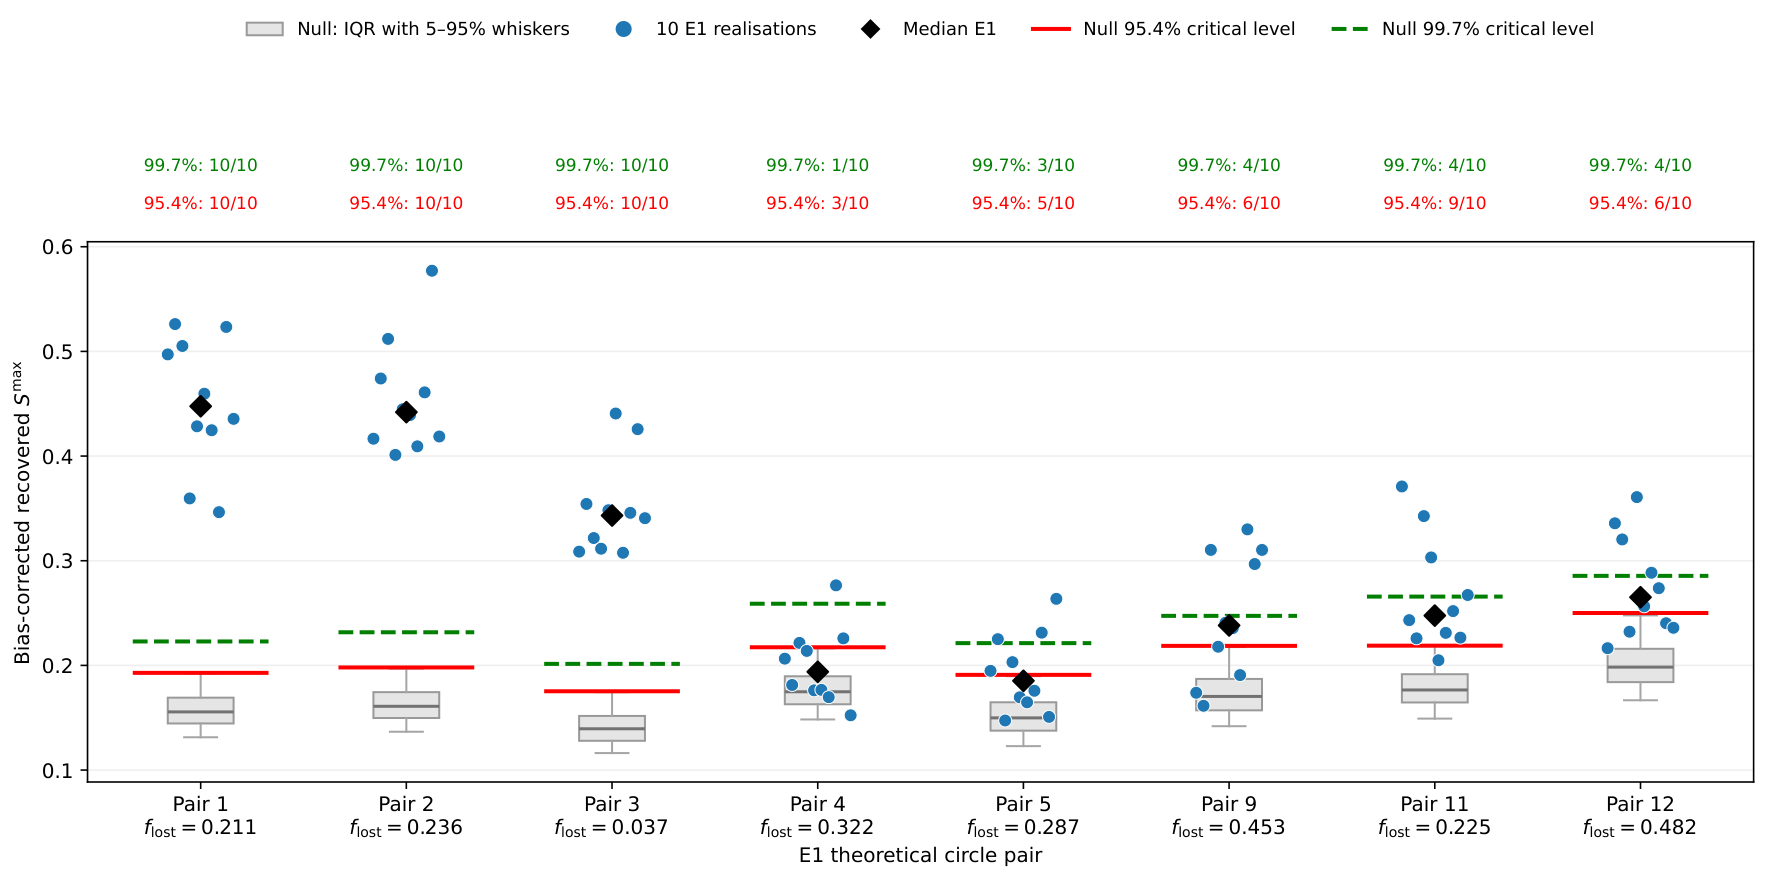

In [9]:
from pathlib import Path

import fitz
from IPython.display import Image, display


# ==================================================
# Saved PDF
# ==================================================

pdf_file = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
    "/inj_e1like_13pairs_1805_nside128_lmax300"
    "/E1_recovery_against_1800_null_boxplot.pdf"
)


# ==================================================
# Render first page of PDF
# ==================================================

document = fitz.open(
    pdf_file
)

page = document[0]

pixmap = page.get_pixmap(
    matrix=fitz.Matrix(2, 2)
)

png_data = pixmap.tobytes(
    "png"
)

document.close()


# ==================================================
# Display figure
# ==================================================

display(
    Image(
        data=png_data
    )
)

## Exact-Inverse Sanity Check

Before testing any regularisation method, the mask-coupling inverse is tested using the exact inverse,

$$
\lambda = 0.
$$

The purpose is to check whether the MASTER-like reconstruction is intrinsically able to recover the true unmasked $S_{\max}$ when the coupling matrix is invertible.

For each circle pair, the recovery error

$$
\Delta S_{\max}
=
S_{\max}^{\rm rec}
-
S_{\max}^{\rm full}
$$

is measured over 1800 E1-like realisations.

If $\Delta S_{\max}$ remains close to zero, the reconstruction formalism itself is working; any later recovery bias can then be attributed to the regularisation rather than to the mask-coupling construction.

In [ ]:
from pathlib import Path

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==================================================
# Paths and settings
# ==================================================

root = Path("/hydrarepo/xluo/circles-in-the-sky")

ensemble_dir = (
    root
    / "inj_e1like_13pairs_1805_nside128_lmax300"
)

map_dir = ensemble_dir / "full_maps"

mask_file = (
    root
    / "src"
    / "COM_Mask_CMB-common-Mask-Int_128_R3.00.fits"
)

pair_table_file = (
    ensemble_dir
    / "e1_13pairs_f_lost_and_relative_error.dat"
)

NPHI = 512
N_REALISATIONS = 1800
MASK_THRESHOLD = 0.5
M_MIN = 2


# ==================================================
# Inputs
# ==================================================

if "calculate_S_curves" not in globals():
    raise RuntimeError(
        "Run your existing calculate_S_curves cell first."
    )

mask = hp.read_map(
    mask_file,
    field=0,
    dtype=np.float64,
)

pair_table = pd.read_csv(
    pair_table_file,
    sep="\t",
)

map_files = sorted(
    map_dir.glob("e1like_r*_nside128_lmax300.fits")
)[:N_REALISATIONS]

if len(map_files) != N_REALISATIONS:
    raise RuntimeError(
        f"Expected {N_REALISATIONS} maps, found {len(map_files)}."
    )


# ==================================================
# Exact inverse: no regularisation
# ==================================================

def apply_exact_inverse(values, eigenvalues):

    scale = np.max(np.abs(eigenvalues))
    minimum = np.min(np.abs(eigenvalues))

    tolerance = (
        100.0
        * np.finfo(float).eps
        * scale
    )

    if minimum <= tolerance:
        return None

    return np.fft.ifft(
        np.fft.fft(values)
        / eigenvalues
    )


# ==================================================
# Load pair-specific matrices
# ==================================================

pair_inputs = {}

for row in pair_table.itertuples(index=False):

    pair = int(row.Pair)
    f_lost = float(row.f_lost)

    if f_lost > 0.5:
        continue

    step3_file = (
        ensemble_dir
        / f"pair{pair:02d}_ensemble_mixing_1800cal.npz"
    )

    with np.load(step3_file) as step3:

        pix_i = step3["pix_ring_i"].copy()
        pix_j = step3["pix_ring_j"].copy()

        M_cross = step3["M_ij"].copy()
        M_i = step3["M_ii"].copy()
        M_j = step3["M_jj"].copy()

    mu_cross = np.fft.fft(M_cross[:, 0])
    mu_i = np.fft.fft(M_i[:, 0])
    mu_j = np.fft.fft(M_j[:, 0])

    all_mu = np.concatenate(
        [mu_cross, mu_i, mu_j]
    )

    condition_number = (
        np.max(np.abs(all_mu))
        / np.min(np.abs(all_mu))
    )

    pair_inputs[pair] = {
        "f_lost": f_lost,
        "pix_i": pix_i,
        "pix_j": pix_j,
        "mu_cross": mu_cross,
        "mu_i": mu_i,
        "mu_j": mu_j,
        "condition_number": condition_number,
    }


# ==================================================
# Apply exact inverse to all 1800 realisations
# ==================================================

result_rows = []

for realisation, map_file in enumerate(map_files):

    full_map = hp.read_map(
        map_file,
        field=0,
        dtype=np.float64,
    )

    masked_map = full_map.copy()
    masked_map[mask < MASK_THRESHOLD] = 0.0

    for pair, inputs in pair_inputs.items():

        pix_i = inputs["pix_i"]
        pix_j = inputs["pix_j"]

        # Full and masked circle modes
        T_i = np.fft.fft(
            full_map[pix_i]
        ) / NPHI

        T_j = np.fft.fft(
            full_map[pix_j]
        ) / NPHI

        T_i_masked = np.fft.fft(
            masked_map[pix_i]
        ) / NPHI

        T_j_masked = np.fft.fft(
            masked_map[pix_j]
        ) / NPHI

        # Full-circle quantities
        full_cross = T_i * T_j
        full_power_i = np.abs(T_i) ** 2
        full_power_j = np.abs(T_j) ** 2

        # Masked pseudo-quantities
        masked_cross = (
            T_i_masked * T_j_masked
        )

        masked_power_i = (
            np.abs(T_i_masked) ** 2
        )

        masked_power_j = (
            np.abs(T_j_masked) ** 2
        )

        # Exact M^{-1}: no regularisation
        recovered_cross = apply_exact_inverse(
            masked_cross,
            inputs["mu_cross"],
        )

        recovered_power_i = apply_exact_inverse(
            masked_power_i,
            inputs["mu_i"],
        )

        recovered_power_j = apply_exact_inverse(
            masked_power_j,
            inputs["mu_j"],
        )

        if any(
            value is None
            for value in [
                recovered_cross,
                recovered_power_i,
                recovered_power_j,
            ]
        ):
            result_rows.append(
                {
                    "Realisation": realisation,
                    "Pair": pair,
                    "f_lost": inputs["f_lost"],
                    "Condition number": (
                        inputs["condition_number"]
                    ),
                    "Status": "singular exact inverse",
                }
            )
            continue

        full_S, full_valid = calculate_S_curves(
            full_cross[None, :],
            full_power_i[None, :],
            full_power_j[None, :],
        )

        recovered_S, recovered_valid = calculate_S_curves(
            recovered_cross[None, :],
            np.real(recovered_power_i)[None, :],
            np.real(recovered_power_j)[None, :],
        )

        if not (
            full_valid[0]
            and recovered_valid[0]
            and np.all(np.isfinite(recovered_S[0]))
        ):
            result_rows.append(
                {
                    "Realisation": realisation,
                    "Pair": pair,
                    "f_lost": inputs["f_lost"],
                    "Condition number": (
                        inputs["condition_number"]
                    ),
                    "Status": "invalid recovered S",
                }
            )
            continue

        full_Smax = float(
            np.max(full_S[0])
        )

        recovered_Smax = float(
            np.max(recovered_S[0])
        )

        result_rows.append(
            {
                "Realisation": realisation,
                "Pair": pair,
                "f_lost": inputs["f_lost"],
                "Condition number": (
                    inputs["condition_number"]
                ),
                "Full Smax": full_Smax,
                "Recovered Smax": recovered_Smax,
                "Delta Smax": (
                    recovered_Smax - full_Smax
                ),
                "Status": "exact inverse",
            }
        )

    if (realisation + 1) % 100 == 0:
        print(
            f"{realisation + 1}/{N_REALISATIONS}"
        )


# ==================================================
# Save results
# ==================================================

results = pd.DataFrame(result_rows)

output_table = (
    ensemble_dir
    / "exact_inverse_1800_recovery_test.dat"
)

results.to_csv(
    output_table,
    sep="\t",
    index=False,
    float_format="%.10e",
)

print("Saved:", output_table)
print(results["Status"].value_counts())


# ==================================================
# Plot Delta Smax by pair
# ==================================================

valid = results.loc[
    results["Status"] == "exact inverse"
].copy()

pairs = sorted(valid["Pair"].unique())

plot_values = [
    valid.loc[
        valid["Pair"] == pair,
        "Delta Smax",
    ].to_numpy()
    for pair in pairs
]

fig, ax = plt.subplots(
    figsize=(12, 5.5)
)

box = ax.boxplot(
    plot_values,
    positions=pairs,
    widths=0.6,
    patch_artist=True,
    showfliers=True,
    flierprops={
        "marker": ".",
        "markersize": 2,
        "alpha": 0.2,
    },
)

for patch in box["boxes"]:
    patch.set_facecolor("tab:blue")
    patch.set_alpha(0.35)

ax.axhline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
)

ax.set_xlabel(
    "Circle-pair index",
    fontsize=16,
)

ax.set_ylabel(
    r"$\Delta S^{\max}"
    r"=S_{\rm rec}^{\max}-S_{\rm full}^{\max}$",
    fontsize=16,
)

ax.tick_params(
    axis="both",
    labelsize=13,
)

ax.grid(
    axis="y",
    alpha=0.25,
)

fig.tight_layout()

output_plot = (
    ensemble_dir
    / "exact_inverse_1800_Delta_Smax.png"
)

fig.savefig(
    output_plot,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:", output_plot)

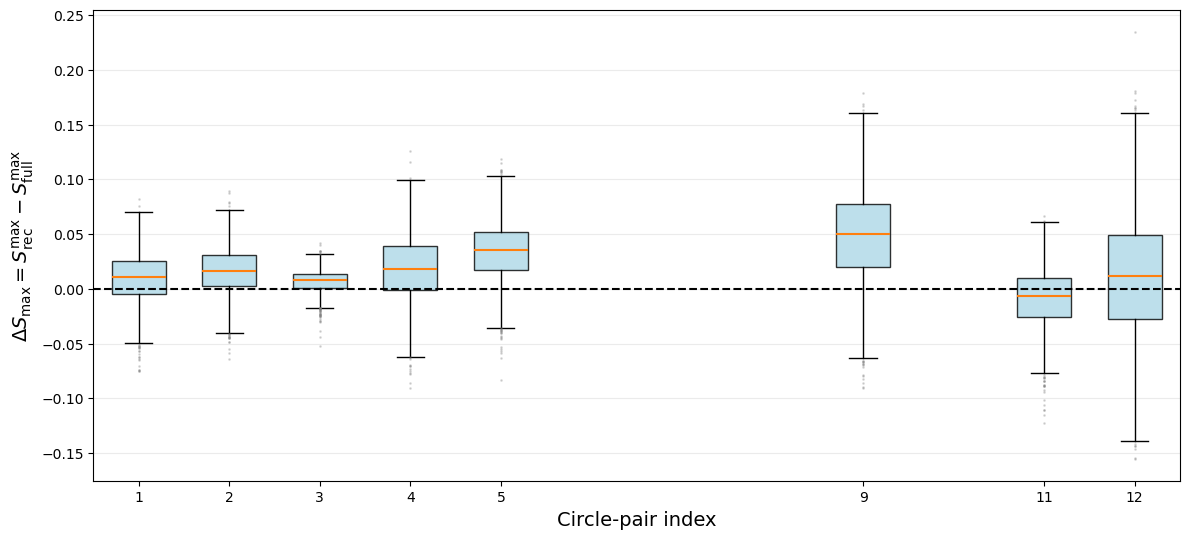

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


# ==================================================
# Load exact-inverse recovery results
# ==================================================

result_file = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
    "/inj_e1like_13pairs_1805_nside128_lmax300"
    "/exact_inverse_1800_recovery_test.dat"
)

data = np.loadtxt(
    result_file,
    skiprows=1,
    usecols=(
        0,
        1,
        2,
        3,
        4,
        5,
        6,
    ),
)


# ==================================================
# Columns
# ==================================================

realisation = data[:, 0].astype(int)
pair = data[:, 1].astype(int)

f_lost = data[:, 2]
condition_number = data[:, 3]

full_smax = data[:, 4]
recovered_smax = data[:, 5]
delta_smax = data[:, 6]


# ==================================================
# Prepare one distribution per circle pair
# ==================================================

pair_indices = np.unique(
    pair
)

box_data = [
    delta_smax[
        pair == pair_index
    ]
    for pair_index in pair_indices
]


# ==================================================
# Plot
# ==================================================

fig, ax = plt.subplots(
    figsize=(12, 5.5)
)

ax.boxplot(
    box_data,
    positions=pair_indices,
    widths=0.6,
    patch_artist=True,
    boxprops=dict(
        facecolor="lightblue",
        alpha=0.8,
    ),
    medianprops=dict(
        color="tab:orange",
        linewidth=1.5,
    ),
    whiskerprops=dict(
        color="black",
    ),
    capprops=dict(
        color="black",
    ),
    flierprops=dict(
        marker=".",
        markersize=2,
        markerfacecolor="gray",
        markeredgecolor="gray",
        alpha=0.25,
    ),
)

ax.axhline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
)

ax.set_xlabel(
    "Circle-pair index",
    fontsize=14,
)

ax.set_ylabel(
    r"$\Delta S_{\max}"
    r" = S_{\rm rec}^{\max} - S_{\rm full}^{\max}$",
    fontsize=14,
)

ax.set_xticks(
    pair_indices
)

ax.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()
plt.show()

## Phase-Scramble Validation

This test checks whether the regularised inverse can **artificially create or enhance a matched-circle signal**.

For the real topology $r001$ pair 13, the Fourier phases of circle $j$ are randomised while its Fourier amplitudes are preserved. This destroys the original phase coherence between the two circles without changing their overall mode power.

Five independent phase-scrambled versions are generated and reconstructed using the same regularisation strength as the original case,

$$
f_{\rm reg}=0.03.
$$

For each scramble, the recovered value is compared directly with the corresponding full-map value,

$$
\Delta S_{\max}
=
S_{\max}^{\rm rec}
-
S_{\max}^{\rm full}.
$$

If $\Delta S_{\max}$ remains small after the true phase relation has been destroyed, the reconstruction is not generating a spurious matched-circle signal by itself.

In [ ]:
from pathlib import Path

import healpy as hp
import numpy as np
import pandas as pd
from IPython.display import display


# ==================================================
# Paths and settings
# ==================================================
root = Path("/hydrarepo/xluo/circles-in-the-sky")

ensemble_dir = (
    root
    / "inj_e1like_13pairs_1805_nside128_lmax300"
)

r001_full_map_file = (
    root
    / "topology_realization_maps_nside128_lmax300"
    / "topology_realization_001_nside128_lmax300.fits"
)

step3_file = (
    ensemble_dir
    / "pair13_ensemble_mixing_1800cal.npz"
)

inverse_file = (
    ensemble_dir
    / "pair13_regularised_inverse.npz"
)

result_file = (
    ensemble_dir
    / "pair13_r001_phase_scrambled_validation.dat"
)

NPHI = 512
M_MIN = 2
N_SCRAMBLES = 5
SCRAMBLE_SEED_BASE = 987654
SELECTED_REGULARISATION_FRACTION = 0.03


# ==================================================
# Phase-scramble one real ring
# ==================================================
def phase_scramble_ring(
    ring,
    random_generator,
):
    ring_modes = np.fft.rfft(ring)
    scrambled_modes = ring_modes.copy()

    random_phases = random_generator.uniform(
        0.0,
        2.0 * np.pi,
        size=len(scrambled_modes) - 2,
    )

    scrambled_modes[1:-1] *= np.exp(
        1.0j * random_phases
    )

    scrambled_modes[-1] *= (
        random_generator.choice([-1.0, 1.0])
    )

    return np.fft.irfft(
        scrambled_modes,
        n=len(ring),
    )


# ==================================================
# Load current pair-13 geometry and eigenvalues
# ==================================================
with np.load(step3_file) as step3:
    pix_ring_i = step3["pix_ring_i"].copy()
    pix_ring_j = step3["pix_ring_j"].copy()
    w_i = step3["w_i"].copy()
    w_j = step3["w_j"].copy()

with np.load(inverse_file) as inverse:
    eigenvalues_ij = inverse[
        "eigenvalues_ij"
    ].copy()

    eigenvalues_ii = inverse[
        "eigenvalues_ii"
    ].copy()

    eigenvalues_jj = inverse[
        "eigenvalues_jj"
    ].copy()


# ==================================================
# Read the actual full topology r001 ring pair
# ==================================================
r001_full_map = hp.read_map(
    r001_full_map_file,
    field=0,
    dtype=np.float64,
)

ring_i = r001_full_map[pix_ring_i]
ring_j_original = r001_full_map[pix_ring_j]


# ==================================================
# Make five phase scrambles of r001 circle j
# ==================================================
full_cross = []
full_power_i = []
full_power_j = []

masked_cross = []
masked_power_i = []
masked_power_j = []

for scramble_id in range(N_SCRAMBLES):
    random_generator = np.random.default_rng(
        SCRAMBLE_SEED_BASE + scramble_id
    )

    ring_j_scrambled = phase_scramble_ring(
        ring_j_original,
        random_generator,
    )

    full_modes_i = np.fft.fft(ring_i) / NPHI
    full_modes_j = (
        np.fft.fft(ring_j_scrambled) / NPHI
    )

    masked_modes_i = (
        np.fft.fft(w_i * ring_i) / NPHI
    )

    masked_modes_j = (
        np.fft.fft(w_j * ring_j_scrambled)
        / NPHI
    )

    full_cross.append(
        full_modes_i * full_modes_j
    )

    full_power_i.append(
        np.abs(full_modes_i) ** 2
    )

    full_power_j.append(
        np.abs(full_modes_j) ** 2
    )

    masked_cross.append(
        masked_modes_i * masked_modes_j
    )

    masked_power_i.append(
        np.abs(masked_modes_i) ** 2
    )

    masked_power_j.append(
        np.abs(masked_modes_j) ** 2
    )


full_cross = np.asarray(full_cross)
full_power_i = np.asarray(full_power_i)
full_power_j = np.asarray(full_power_j)

masked_cross = np.asarray(masked_cross)
masked_power_i = np.asarray(masked_power_i)
masked_power_j = np.asarray(masked_power_j)


# ==================================================
# Full phase-scrambled r001 S(beta)
# ==================================================
full_S, full_valid = calculate_S_curves(
    full_cross,
    full_power_i,
    full_power_j,
)


# ==================================================
# Apply the same f_reg = 0.03 inverse used for r001
# ==================================================
recovered_cross, _, _ = apply_regularised_inverse(
    masked_cross,
    eigenvalues_ij,
    SELECTED_REGULARISATION_FRACTION,
)

recovered_power_i, _, _ = (
    apply_regularised_inverse(
        masked_power_i,
        eigenvalues_ii,
        SELECTED_REGULARISATION_FRACTION,
    )
)

recovered_power_j, _, _ = (
    apply_regularised_inverse(
        masked_power_j,
        eigenvalues_jj,
        SELECTED_REGULARISATION_FRACTION,
    )
)

recovered_S, recovered_valid = calculate_S_curves(
    recovered_cross,
    np.real(recovered_power_i),
    np.real(recovered_power_j),
)

valid = (
    full_valid
    & recovered_valid
    & np.all(np.isfinite(full_S), axis=1)
    & np.all(np.isfinite(recovered_S), axis=1)
)

if not np.all(valid):
    raise RuntimeError(
        "At least one r001 phase-scrambled "
        "S curve is invalid."
    )


# ==================================================
# Direct result
# ==================================================
full_Smax = np.max(full_S, axis=1)
recovered_Smax = np.max(recovered_S, axis=1)

scrambled_table = pd.DataFrame(
    {
        "Map": ["topology r001"] * N_SCRAMBLES,
        "Scramble": np.arange(N_SCRAMBLES),
        "Full scrambled Smax": full_Smax,
        "Recovered scrambled Smax": recovered_Smax,
        "Recovered minus full": (
            recovered_Smax - full_Smax
        ),
    }
)

scrambled_table.to_csv(
    result_file,
    sep="\t",
    index=False,
    float_format="%.10e",
)

display(
    scrambled_table.style.format(
        {
            "Full scrambled Smax": "{:.6f}",
            "Recovered scrambled Smax": "{:.6f}",
            "Recovered minus full": "{:.6f}",
        }
    )
)

print()
print(
    "Selected regularisation fraction:",
    SELECTED_REGULARISATION_FRACTION,
)
print("Saved:", result_file)

In [12]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# ==================================================
# Saved phase-scramble validation table
# ==================================================

result_file = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
    "/inj_e1like_13pairs_1805_nside128_lmax300"
    "/pair13_r001_phase_scrambled_validation.dat"
)


# ==================================================
# Load and display
# ==================================================

table = pd.read_csv(
    result_file,
    sep="\t",
)

display(
    table.style.format(
        {
            "Full scrambled Smax": "{:.6f}",
            "Recovered scrambled Smax": "{:.6f}",
            "Recovered minus full": "{:.6f}",
        }
    )
)

,Map,Scramble,Full scrambled Smax,Recovered scrambled Smax,Recovered minus full
0,topology r001,0,0.174102,0.211329,0.037227
1,topology r001,1,0.137793,0.187259,0.049466
2,topology r001,2,0.173896,0.220216,0.046320
3,topology r001,3,0.143332,0.193833,0.050501
4,topology r001,4,0.164112,0.245006,0.080894
